In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import plotly.express as px

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("../data/processed/cleaned_sales.csv")

df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,category,sub_category,product_name,sales,year,month,month_name,quarter,weekday,shipping_days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,4,Wednesday,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,4,Wednesday,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,2,Monday,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,4,Tuesday,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,4,Tuesday,7


In [3]:
city_summary = (
    df.groupby(["city","state"])
    .agg(
        Total_Sales=("sales","sum"),
        Orders=("order_id","nunique"),
        Customers=("customer_id","nunique"),
        Average_Sale=("sales","mean")
    )
    .reset_index()
)

city_summary.head()

,city,state,Total_Sales,Orders,Customers,Average_Sale
0,Aberdeen,South Dakota,25.500,1,1,25.500000
1,Abilene,Texas,1.392,1,1,1.392000
2,Akron,Ohio,2724.244,9,9,136.212200
3,Albuquerque,New Mexico,2220.160,7,7,158.582857
4,Alexandria,Virginia,5519.570,6,6,344.973125


In [4]:
city_summary["Sales_per_Customer"] = (
    city_summary["Total_Sales"] /
    city_summary["Customers"]
)

In [5]:
city_summary["Sales_per_Order"] = (
    city_summary["Total_Sales"] /
    city_summary["Orders"]
)

In [6]:
city_summary["Demand_Score"] = (
    city_summary["Total_Sales"] *
    city_summary["Customers"] /
    city_summary["Orders"]
)

In [7]:
city_summary["Sales_Rank"] = city_summary["Total_Sales"].rank(pct=True)

city_summary["Customer_Rank"] = city_summary["Customers"].rank(pct=True)

city_summary["Demand_Rank"] = city_summary["Demand_Score"].rank(pct=True)

city_summary["AOV_Rank"] = city_summary["Sales_per_Order"].rank(pct=True)

In [8]:
city_summary["Opportunity_Score"] = (
    0.40 * city_summary["Sales_Rank"] +
    0.25 * city_summary["Customer_Rank"] +
    0.25 * city_summary["Demand_Rank"] +
    0.10 * city_summary["AOV_Rank"]
)

In [9]:
top10 = (
    city_summary
    .sort_values("Opportunity_Score", ascending=False)
    .head(10)
)

top10

,city,state,Total_Sales,Orders,Customers,Average_Sale,Sales_per_Customer,Sales_per_Order,Demand_Score,Sales_Rank,Customer_Rank,Demand_Rank,AOV_Rank,Opportunity_Score
251,Jacksonville,Florida,39133.328,38,38,521.777707,1029.824421,1029.824421,39133.328000,0.985000,0.981667,0.985000,0.926667,0.978333
377,New York City,New York,252462.547,439,349,283.347415,723.388387,575.085528,200704.849437,1.000000,1.000000,1.000000,0.771667,0.977167
143,Detroit,Michigan,42446.944,53,50,369.103861,848.938880,800.885736,40044.286792,0.986667,0.983333,0.986667,0.868333,0.974000
514,Seattle,Washington,116106.322,210,187,272.550052,620.889422,552.887248,103389.915305,0.996667,0.993333,0.996667,0.766667,0.972833
496,San Antonio,Texas,21843.528,27,27,370.229288,809.019556,809.019556,21843.528000,0.983333,0.973333,0.983333,0.875000,0.970000
310,Los Angeles,California,173420.181,378,300,238.214534,578.067270,458.783548,137635.064286,0.998333,0.998333,0.998333,0.695000,0.968000
378,Newark,Delaware,20319.980,28,28,356.490877,725.713571,725.713571,20319.980000,0.981667,0.975833,0.981667,0.846667,0.966708
499,San Diego,California,47521.029,88,86,279.535465,552.570105,540.011693,46441.005614,0.988333,0.988333,0.990000,0.755000,0.965417
23,Atlanta,Georgia,17197.840,17,17,440.970256,1011.637647,1011.637647,17197.840000,0.976667,0.949167,0.976667,0.921667,0.964292
500,San Francisco,California,109041.120,261,230,218.082240,474.091826,417.782069,96089.875862,0.995000,0.995000,0.993333,0.640000,0.959083


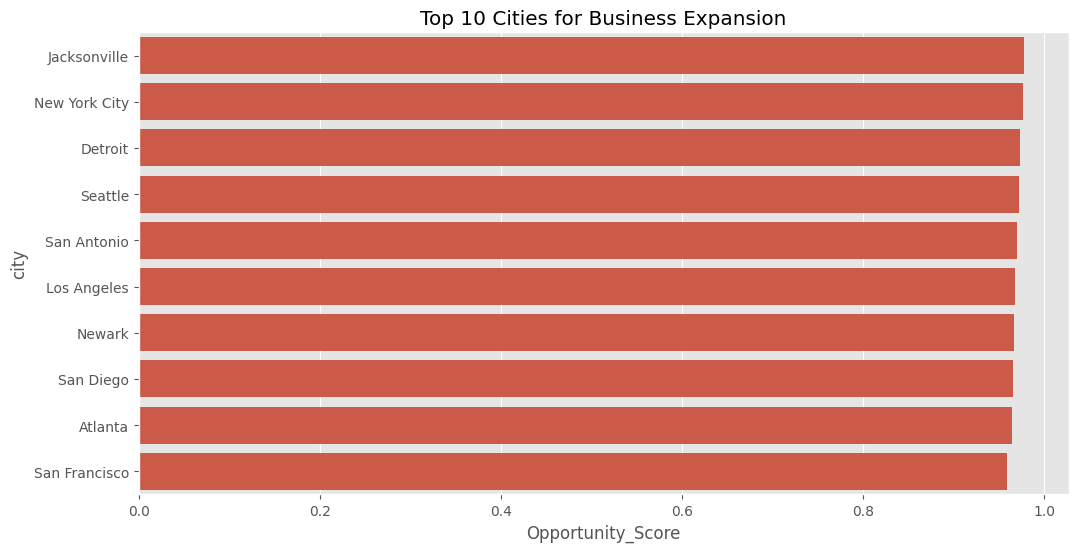

In [10]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top10,
    x="Opportunity_Score",
    y="city"
)

plt.title("Top 10 Cities for Business Expansion")

plt.show()

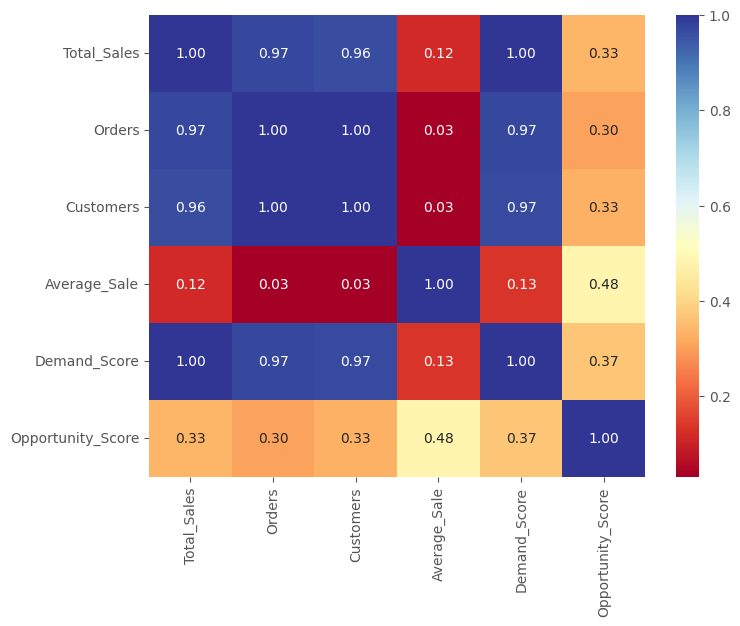

In [11]:
corr = city_summary[
    [
        "Total_Sales",
        "Orders",
        "Customers",
        "Average_Sale",
        "Demand_Score",
        "Opportunity_Score"
    ]
].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="RdYlBu",
    fmt=".2f"
)

plt.show()

In [12]:
features = city_summary[
    [
        "Total_Sales",
        "Orders",
        "Customers",
        "Average_Sale",
        "Demand_Score"
    ]
]

In [13]:
scaler = StandardScaler()

scaled = scaler.fit_transform(features)

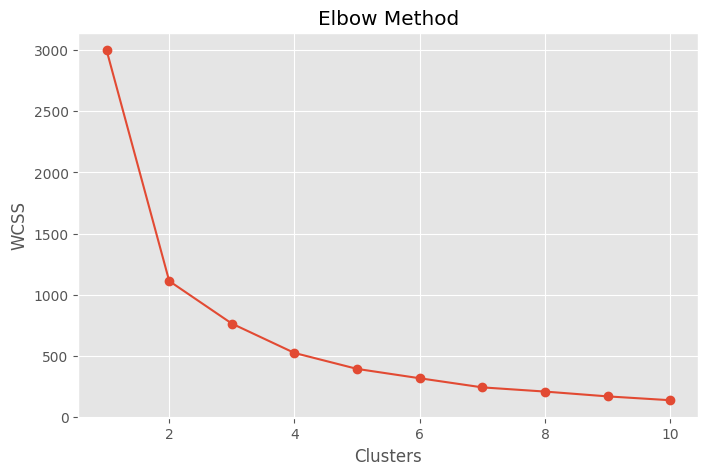

In [14]:
wcss = []

for i in range(1,11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(8,5))

plt.plot(range(1,11),wcss,marker="o")

plt.xlabel("Clusters")

plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.show()

In [15]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

city_summary["Cluster"] = kmeans.fit_predict(scaled)

In [16]:
cluster_sales = city_summary.groupby("Cluster")["Total_Sales"].mean()
cluster_sales

Cluster
0      7510.925090
1      1616.615572
2    137304.676967
Name: Total_Sales, dtype: float64

In [17]:
cluster_order = cluster_sales.sort_values().index.tolist()

cluster_map = {
    cluster_order[0]: "Low Potential",
    cluster_order[1]: "Medium Potential",
    cluster_order[2]: "High Potential"
}

city_summary["Cluster"] = city_summary["Cluster"].map(cluster_map)

In [18]:
fig = px.scatter(
    city_summary,
    x="Customers",
    y="Total_Sales",
    color="Cluster",
    size="Demand_Score",
    hover_data=["city","state"],
    title="City Opportunity Clusters"
)

fig.show()

In [19]:
fig = px.scatter(
    city_summary,
    x="Orders",
    y="Sales_per_Order",
    size="Total_Sales",
    color="Cluster",
    hover_name="city",
    title="Orders vs Average Order Value"
)

fig.show()

In [20]:
recommendation = (
    city_summary
    .sort_values("Opportunity_Score", ascending=False)
    [
        [
            "city",
            "state",
            "Total_Sales",
            "Customers",
            "Orders",
            "Opportunity_Score",
            "Cluster"
        ]
    ]
)

recommendation.head(15)

,city,state,Total_Sales,Customers,Orders,Opportunity_Score,Cluster
251,Jacksonville,Florida,39133.328,38,38,0.978333,Medium Potential
377,New York City,New York,252462.547,349,439,0.977167,High Potential
143,Detroit,Michigan,42446.944,50,53,0.974000,Medium Potential
514,Seattle,Washington,116106.322,187,210,0.972833,High Potential
496,San Antonio,Texas,21843.528,27,27,0.970000,Medium Potential
310,Los Angeles,California,173420.181,300,378,0.968000,High Potential
378,Newark,Delaware,20319.980,28,28,0.966708,Medium Potential
499,San Diego,California,47521.029,86,88,0.965417,Medium Potential
23,Atlanta,Georgia,17197.840,17,17,0.964292,Medium Potential
500,San Francisco,California,109041.120,230,261,0.959083,High Potential


In [21]:
recommendation.to_csv(
    "../data/processed/business_recommendations.csv",
    index=False
)

city_summary.to_csv(
    "../data/processed/city_analysis.csv",
    index=False
)

print("Business analysis completed successfully.")

Business analysis completed successfully.
